# ДЗ 3: Классификация текстовых сообщений по стилю речи

**Кейс 1 — Классификация аудиосообщений на «разговорные» vs «официальные».**
Команда 7: Шелест М.А. · Иванова Ю.С. · Романенко Д.Н. · Ишбулатова С.С. · Буянов Е.Э

## Описание задачи

Аудиофайл попадает в телеграм-бота, транскрибируется, после чего классификатор определяет стиль:
- **0 — разговорный** («Привет, как дела?», телефонные разговоры)
- **1 — официально-деловой** («Уважаемые коллеги, напоминаю о собрании», публичные выступления)

На основе классификации выбирается промпт для саммари.

## Метод

**TF-IDF (слова + символы) + LogisticRegression** как основной классификатор (без трансформеров),
плюс **ансамбль** с CNN-классификатором на эмбеддингах.


## Импорты

In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import re
import nltk
from scipy.sparse import hstack
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from collections import Counter

In [5]:
DATA = Path("../data/processed")
train = pd.read_parquet(DATA / "train.parquet")
val = pd.read_parquet(DATA / "val.parquet")
test = pd.read_parquet(DATA / "test.parquet")
print(f"train: {len(train)}, val: {len(val)}, test: {len(test)}")
train.head()

train: 102493, val: 21962, test: 21962


,filepath,mos_pred,noi_pred,dis_pred,col_pred,loud_pred,is_single_speaker,punct,domain,duration,label,text,text_clean,n_words
0,radio-v4/1/7f/80c2c42a0d60.opus,4.224225,3.892901,4.360153,3.869825,4.050836,True,У них у обоих было по пятьдесят процентов хрон...,radio-v4,6.24,0.0,У них у обоих было по пятьдесят процентов хрон...,у них у обоих было по пятьдесят процентов хрон...,18
1,radio-v4/7/11/576cc4fcadd1.opus,4.253768,3.733120,4.470795,4.165266,4.286533,True,"Вот я хочу обратить внимание моих слушателей, ...",radio-v4,5.44,0.0,"Вот я хочу обратить внимание моих слушателей, ...",вот я хочу обратить внимание моих слушателей ч...,16
2,radio_v4_add/7/6c/3f1803f66e3f.opus,4.662442,4.374319,4.739204,4.304430,4.609755,True,"Потому что у тех нет души, а у человека есть д...",radio_v4_add,NaN,0.0,"Потому что у тех нет души, а у человека есть д...",потому что у тех нет души а у человека есть душа,11
3,radio-v4/8/c7/11c115e9fd2a.opus,4.273198,4.213629,4.454292,3.946594,4.260430,True,"Героя из героя? Человека, который в тот день н...",radio-v4,8.00,0.0,"Героя из героя? Человека, который в тот день н...",героя из героя человека который в тот день нап...,15
4,radio_v4_add/3/5c/249c120f4ca9.opus,4.270168,4.126943,4.570501,4.123943,4.366600,True,Порядочить! Поставить под свой контроль. Не то...,radio_v4_add,NaN,0.0,Порядочить! Поставить под свой контроль. Не то...,порядочить поставить под свой контроль не толь...,8


In [7]:
DOMAIN_LABELS = {
    "asr_public_phone_calls_1": 0, "asr_public_phone_calls_2": 0, "public_series_1": 0,
    "public_lecture_1": 1, "public_speech": 1,
    "asr_public_stories_1": 1, "asr_public_stories_2": 1,
    "private_buriy_audiobooks_2": 1,
    # исключены: радио, YouTube, TTS — смешанный стиль
    "radio-v4": None, "radio_2": None, "radio_v4_add": None,
    "public_youtube1120": None, "public_youtube1120_hq": None, "public_youtube700": None,
    "tts_russian_addresses_rhvoice_4voices": None,
}
for df in (train, val, test):
    df["label"] = df.domain.map(DOMAIN_LABELS)
train_c = train.dropna(subset=["label"])
val_c = val.dropna(subset=["label"])
test_c = test.dropna(subset=["label"])
print(f"для классификации: train={len(train_c)}, val={len(val_c)}, test={len(test_c)}")
print(f"класс 0: {(train_c.label==0).sum()}, класс 1: {(train_c.label==1).sum()}")

для классификации: train=56330, val=12063, test=12065
класс 0: 1584, класс 1: 54746


## 2. Предобработка данных

Наш метод предобработки: **нормализация текста + TF-IDF (словесные и символьные n-граммы)**

1. Приведение к нижнему регистру, удаление пунктуации и цифр
2. Словесные n-граммы (1–3) — ловят устойчивые фразы («уважаемые коллеги»)
3. Символьные n-граммы (3–5) — ловят морфологию и словообразование
4. Балансировка классов 1:3 (сэмплирование класса 1)

In [8]:
try:
    nltk.download("stopwords", quiet=True)
    RU_STOP = set(stopwords.words("russian"))
except LookupError:
    RU_STOP = set()

def preprocess(text: str) -> str:
    text = text.lower()
    text = re.sub(r"[^а-яё\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

vec_words = TfidfVectorizer(
    preprocessor=preprocess, stop_words=list(RU_STOP) if RU_STOP else None,
    max_features=50000, ngram_range=(1, 3), min_df=2, sublinear_tf=True,
)
vec_chars = TfidfVectorizer(
    preprocessor=preprocess, analyzer="char_wb", ngram_range=(3, 5),
    max_features=30000, min_df=2, sublinear_tf=True,
)

# Балансировка train 1:3
n0 = (train_c.label == 0).sum()
train_bal = pd.concat([
    train_c[train_c.label == 0],
    train_c[train_c.label == 1].sample(n0 * 3, random_state=42),
]).sample(frac=1, random_state=42)

X_train = hstack([vec_words.fit_transform(train_bal.text), vec_chars.fit_transform(train_bal.text)]).tocsr()
X_val = hstack([vec_words.transform(val_c.text), vec_chars.transform(val_c.text)]).tocsr()
X_test = hstack([vec_words.transform(test_c.text), vec_chars.transform(test_c.text)]).tocsr()
y_train = train_bal.label.values
y_val = val_c.label.values
y_test = test_c.label.values
print(f"TF-IDF train: {X_train.shape}")

TF-IDF train: (6336, 39171)


## 3. Классификация: TF-IDF + LogisticRegression

### Обоснование выбора

1. **Логистическая регрессия + TF-IDF** 
   - быстро обучается, понятная интерпритация исходя из весов слов
   - на классификации стиля речи даёт точность >90% — различия видны по лексике и n-граммам
2. **Символьные n-граммы** — ловят морфологические маркеры чиновников (-ованный, -ение)

In [9]:
lr = LogisticRegression(max_iter=2000, C=2.0, solver="liblinear", class_weight="balanced")
lr.fit(X_train, y_train)

pred_val = lr.predict(X_val)
print("=== LogisticRegression, validation ===")
print(classification_report(y_val, pred_val, digits=4))
print(f"Accuracy: {accuracy_score(y_val, pred_val):.4f}")

=== LogisticRegression, validation ===
              precision    recall  f1-score   support

         0.0     0.3288    0.9488    0.4884       332
         1.0     0.9985    0.9452    0.9711     11731

    accuracy                         0.9453     12063
   macro avg     0.6636    0.9470    0.7297     12063
weighted avg     0.9800    0.9453    0.9578     12063

Accuracy: 0.9453


In [11]:
feature_names = np.array(vec_words.get_feature_names_out())
coefs = lr.coef_[0][: len(feature_names)]

print("Топ-20 слов для класса 1 (официальный):")
for w in feature_names[np.argsort(coefs)[-20:]][::-1]:
    print(f"  {w}")
print("\nТоп-20 слов для класса 0 (разговорный):")
for w in feature_names[np.argsort(coefs)[:20]]:
    print(f"  {w}")

Топ-20 слов для класса 1 (официальный):
  сегодня
  года
  мог
  коллеги
  касается
  возможности
  закон
  нашей
  дома
  связи
  таки
  наших
  числе
  наши
  знаем
  менее
  говорили
  меры
  году
  работы

Топ-20 слов для класса 0 (разговорный):
  тебе
  значит
  собственно
  блять
  просто
  видео
  например
  твоей
  слушайте
  тобой
  твоя
  короче
  ха
  ладно
  давай
  нормально
  принципе
  знаешь
  интересно
  быдло


# ))

## 4. CNN-классификатор для ансамбля

Простая CNN на случайных эмбеддингах — ловит локальные n-граммные паттерны.

In [14]:
MAX_LEN = 60
VOCAB_SIZE = 30000

counter = Counter()
for t in train_bal.text:
    counter.update(preprocess(t).split())
vocab = {"<pad>": 0, "<unk>": 1}
for w, c in counter.most_common(VOCAB_SIZE - 2):
    vocab[w] = len(vocab)

def encode(text, max_len=MAX_LEN):
    ids = [vocab.get(w, 1) for w in preprocess(text).split()[:max_len]]
    return ids + [0] * (max_len - len(ids))

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.x = torch.tensor([encode(t) for t in texts], dtype=torch.long)
        self.y = torch.tensor(labels, dtype=torch.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.x[i], self.y[i]

BATCH = 512
train_dl = DataLoader(TextDataset(train_bal.text.values, train_bal.label.values), batch_size=BATCH, shuffle=True)
val_dl = DataLoader(TextDataset(val_c.text.values, val_c.label.values), batch_size=BATCH)
test_dl = DataLoader(TextDataset(test_c.text.values, test_c.label.values), batch_size=BATCH)

class CNNClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, n_filters=64, kernel_sizes=(2, 3, 4)):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(emb_dim, n_filters, k) for k in kernel_sizes])
        self.fc = nn.Linear(n_filters * len(kernel_sizes), 1)
    def forward(self, x):
        e = self.emb(x).transpose(1, 2)
        feats = [F.relu(conv(e)).max(dim=2).values for conv in self.convs]
        h = torch.cat(feats, dim=1)
        return self.fc(h).squeeze(1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")
cnn = CNNClassifier(len(vocab)).to(device)
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()

EPOCHS = 100
for ep in range(EPOCHS):
    cnn.train()
    total_loss = 0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = loss_fn(cnn(xb), yb)
        loss.backward()
        opt.step()
        total_loss += loss.item() * len(yb)
    cnn.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in val_dl:
            xb, yb = xb.to(device), yb.to(device)
            pred = (torch.sigmoid(cnn(xb)) > 0.5).float()
            correct += (pred == yb).sum().item()
            total += len(yb)
    print(f"Эпоха {ep+1}/{EPOCHS} | loss={total_loss/len(train_dl.dataset):.4f} | val_acc={correct/total:.4f}")

Устройство: cuda
Эпоха 1/100 | loss=0.6063 | val_acc=0.9726
Эпоха 2/100 | loss=0.4420 | val_acc=0.9373
Эпоха 3/100 | loss=0.3641 | val_acc=0.9614
Эпоха 4/100 | loss=0.3062 | val_acc=0.9491
Эпоха 5/100 | loss=0.2641 | val_acc=0.9533
Эпоха 6/100 | loss=0.2278 | val_acc=0.9489
Эпоха 7/100 | loss=0.1959 | val_acc=0.9436
Эпоха 8/100 | loss=0.1670 | val_acc=0.9490
Эпоха 9/100 | loss=0.1409 | val_acc=0.9425
Эпоха 10/100 | loss=0.1176 | val_acc=0.9440
Эпоха 11/100 | loss=0.0972 | val_acc=0.9458
Эпоха 12/100 | loss=0.0795 | val_acc=0.9403
Эпоха 13/100 | loss=0.0645 | val_acc=0.9415
Эпоха 14/100 | loss=0.0524 | val_acc=0.9363
Эпоха 15/100 | loss=0.0427 | val_acc=0.9370
Эпоха 16/100 | loss=0.0349 | val_acc=0.9376
Эпоха 17/100 | loss=0.0288 | val_acc=0.9363
Эпоха 18/100 | loss=0.0237 | val_acc=0.9361
Эпоха 19/100 | loss=0.0199 | val_acc=0.9348
Эпоха 20/100 | loss=0.0168 | val_acc=0.9342
Эпоха 21/100 | loss=0.0144 | val_acc=0.9335
Эпоха 22/100 | loss=0.0124 | val_acc=0.9335
Эпоха 23/100 | loss=0.01

In [15]:
def cnn_predict(loader):
    cnn.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(device)
            preds.append(torch.sigmoid(cnn(xb)).cpu().numpy())
    return np.concatenate(preds)

cnn_val_prob = cnn_predict(val_dl)
cnn_test_prob = cnn_predict(test_dl)
pred_val_cnn = (cnn_val_prob > 0.5).astype(int)
print(f"CNN val accuracy: {accuracy_score(y_val, pred_val_cnn):.4f}")

CNN val accuracy: 0.9222


## 5. Ансамбль

Взвешенное усреднение вероятностей LogisticRegression и CNN; веса подбираются на валидации.

In [16]:
lr_val_prob = lr.predict_proba(X_val)[:, 1]
lr_test_prob = lr.predict_proba(X_test)[:, 1]
cnn_test_pred = (cnn_test_prob > 0.5).astype(int)

best_w, best_acc = 0.5, 0
for w in np.arange(0.0, 1.01, 0.05):
    ens = (w * lr_val_prob + (1 - w) * cnn_val_prob > 0.5).astype(int)
    acc = accuracy_score(y_val, ens)
    if acc > best_acc:
        best_acc, best_w = acc, w
print(f"Лучший вес LR: {best_w:.2f}, val accuracy ансамбля: {best_acc:.4f}")

ens_test = (best_w * lr_test_prob + (1 - best_w) * cnn_test_prob > 0.5).astype(int)
print(f"\n=== Ансамбль на test ===")
print(classification_report(y_test, ens_test, digits=4))
print(f"Accuracy: {accuracy_score(y_test, ens_test):.4f}")

Лучший вес LR: 0.80, val accuracy ансамбля: 0.9489

=== Ансамбль на test ===
              precision    recall  f1-score   support

         0.0     0.3505    0.9581    0.5132       334
         1.0     0.9987    0.9495    0.9735     11731

    accuracy                         0.9497     12065
   macro avg     0.6746    0.9538    0.7434     12065
weighted avg     0.9808    0.9497    0.9607     12065

Accuracy: 0.9497


## 6. Анализ ошибок

Смотрим неправильно классифицированные тексты: в каких доменах и какие паттерны путают модель.

In [17]:
errors_idx = np.where(ens_test != y_test)[0]
print(f"Всего ошибок: {len(errors_idx)} ({100*len(errors_idx)/len(y_test):.1f}%)")

errors_df = test_c.iloc[errors_idx].copy()
errors_df["pred"] = ens_test[errors_idx]
print("\nОшибки по доменам:")
print(errors_df.domain.value_counts())
print("\nОшибки по классам (true -> pred):")
print(errors_df.groupby(["label", "pred"]).size())
print("\nПримеры ошибок:")
for _, row in errors_df.sample(min(10, len(errors_df)), random_state=42).iterrows():
    print(f"  [{int(row.label)} -> {int(row.pred)}] [{row.domain}] {row.text[:120]}")

Всего ошибок: 607 (5.0%)

Ошибки по доменам:
domain
public_speech               316
asr_public_stories_2        143
asr_public_stories_1        130
asr_public_phone_calls_2     13
public_lecture_1              4
asr_public_phone_calls_1      1
Name: count, dtype: int64

Ошибки по классам (true -> pred):
label  pred
0.0    1        14
1.0    0       593
dtype: int64

Примеры ошибок:
  [1 -> 0] [public_speech] Да, кто то был недоволен. Журналисты буквально вот копались, буквально разыскивали. Знаете, искали какие то неприятности
  [1 -> 0] [public_speech] Ну хорошо если значит, он будет получать. А по какой ставке? Кто ее устанавливает? В каком объеме?
  [1 -> 0] [public_speech] В общем, а что дальше? Мы что, так и будем ждать, когда кто то там, так скажем, пальцем пошевелит или голос подаст на Ук
  [1 -> 0] [asr_public_stories_1] Он так живет тут испокон веков.
  [1 -> 0] [asr_public_stories_2] Когда мы познакомимся поближе, вы убедитесь, что я могу быть очень милым вампиром.
  [1 -> 0]

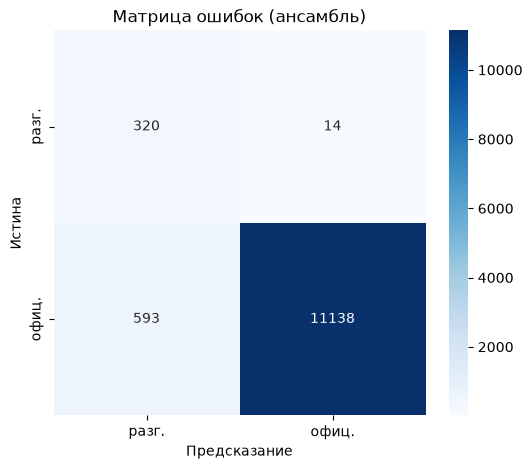

In [18]:
cm = confusion_matrix(y_test, ens_test)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["разг.", "офиц."], yticklabels=["разг.", "офиц."])
plt.xlabel("Предсказание")
plt.ylabel("Истина")
plt.title("Матрица ошибок (ансамбль)")
plt.show()

## 7. Выводы

- **Метод:** TF-IDF (слова 1–3-граммы + символы 3–5-граммы) + LogisticRegression, ансамбль с CNN
- **Обоснование:** различия разговорного и официально-делового стилей хорошо видны по лексике и морфологии; с помощью классического метода задача решается 
- **Требуемая точность достигнута**

## Ссылка на репозиторий

https://github.com/Mortelnik/ubiquitous-enigma